# 3. 예측 모델 비교

2단계에서 찾은 패턴(요일, 추세, 이벤트, 공휴일)을 입력 컬럼으로 만들고, 단순한 예측 방법과 회귀 모델을 비교

## 3-1. 입력 컬럼 만들기


| 컬럼 | 내용 |
|---|---|
| cnt | 그날 주문 수 (맞혀야 할 값) |
| weekday | 요일 (0: 일 ~ 6: 토) |
| trend | 분석 기간 중 며칠째인지 (1 ~ 594) |
| event_peak | 2017-11-24만 1 |
| event_after | 2017-11-25 ~ 11-29만 1 |
| event_strike | 2018-05-21 ~ 05-31만 1 |
| holiday | 브라질 공휴일 + 12/24, 12/31이면 1 |

- holiday: `holidays` 라이브러리의 브라질 공식 공휴일에 이브 2일을 직접 추가 (공식 공휴일은 아니지만 2단계에서 급감 확인)
- 공휴일은 데이터에서 빼지 않고 표시만 함

In [6]:
import sqlite3
import pandas as pd
import holidays

conn = sqlite3.connect('/Users/gon-i/Desktop/olist.db')

query = """
with daily as (
    select
        date(order_purchase_timestamp) as order_date,
        count(*) as cnt
    from orders
    where date(order_purchase_timestamp) between '2017-01-05' and '2018-08-21'
    group by order_date
)
select
    order_date,
    cnt,
    cast(strftime('%w', order_date) as integer) as weekday,
    row_number() over (order by order_date) as trend,
    case when order_date = '2017-11-24' then 1 else 0 end as event_peak,
    case when order_date between '2017-11-25' and '2017-11-29' then 1 else 0 end as event_after,
    case when order_date between '2018-05-21' and '2018-05-31' then 1 else 0 end as event_strike
from daily
order by order_date
"""
df = pd.read_sql(query, conn)
conn.close()

df['order_date'] = pd.to_datetime(df['order_date'])

br_holidays = holidays.Brazil(years=[2017, 2018])
holiday_dates = set(br_holidays.keys())
holiday_dates.update([
    pd.to_datetime('2017-12-24').date(),
    pd.to_datetime('2017-12-31').date(),
])
df['holiday'] = df['order_date'].dt.date.isin(holiday_dates).astype(int)

print('공휴일 수:', df['holiday'].sum())
print(df.groupby('holiday')['cnt'].mean().round(1))

공휴일 수: 14
holiday
0    166.8
1    118.9
Name: cnt, dtype: float64


## 3-2. 학습 기간 / 테스트 기간

| 구분 | 기간 | 일수 |
|---|---|---|
| 학습 | 2017-01-05 ~ 2018-06-26 | 538일 |
| 테스트 | 2018-06-27 ~ 2018-08-21 | 56일 (마지막 8주) |

- 날짜 순서대로 나눔
- 이벤트, 공휴일은 전부 학습 기간에 있고 테스트 기간엔 없음 → 평범한 날을 얼마나 맞히는지 보는 테스트

In [2]:
%pip install holidays

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 10.8 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [7]:
test_start = pd.to_datetime('2018-06-27')

train = df[df['order_date'] < test_start].copy()
test = df[df['order_date'] >= test_start].copy()

print('공부 기간:', train['order_date'].min().date(), '~', train['order_date'].max().date(), '/', len(train), '일')
print('시험 기간:', test['order_date'].min().date(), '~', test['order_date'].max().date(), '/', len(test), '일')

공부 기간: 2017-01-05 ~ 2018-06-26 / 538 일
시험 기간: 2018-06-27 ~ 2018-08-21 / 56 일


## 3-3. 베이스라인 예측

| 베이스라인 | 방법 |
|---|---|
| A (`pred_last_week`) | 지난주 같은 요일 실제 값 |
| B (`pred_4week_avg`) | 최근 4주 같은 요일 실제 값 평균 |

- 2단계에서 요일 차이가 커서 같은 요일끼리 사용
- 테스트 기간 첫 주의 지난주 값은 학습 기간에 있어서, 전체 df에서 먼저 계산하고 테스트 기간만 잘라냄
- 594일이 빠짐없이 날짜순이라 `shift(7)` = 7일 전 값
- 베이스라인은 테스트 기간 중에도 직전 주 실제 값을 씀. 회귀 모델은 6/26까지만 학습하고 56일을 한 번에 예측해서, 베이스라인이 정보를 더 많이 쓰는 조건

In [5]:
df = df.sort_values('order_date').reset_index(drop=True)

# 기준선 A: 지난주 같은 요일 값
df['pred_last_week'] = df['cnt'].shift(7)

# 기준선 B: 최근 4주 같은 요일 평균 (7, 14, 21, 28일 전)
df['pred_4week_avg'] = (
    df['cnt'].shift(7) + df['cnt'].shift(14) +
    df['cnt'].shift(21) + df['cnt'].shift(28)
) / 4

test = df[df['order_date'] >= test_start].copy()

print(test[['pred_last_week', 'pred_4week_avg']].isna().sum())

check = df[df['order_date'].isin(pd.to_datetime(['2018-06-25', '2018-07-02']))]
print(check[['order_date', 'weekday', 'cnt', 'pred_last_week', 'pred_4week_avg']])

pred_last_week    0
pred_4week_avg    0
dtype: int64
    order_date  weekday  cnt  pred_last_week  pred_4week_avg
536 2018-06-25        1  241           246.0           227.0
543 2018-07-02        1  195           241.0           251.5


In [8]:
df = df.sort_values('order_date').reset_index(drop=True)

df['pred_last_week'] = df['cnt'].shift(7)
df['pred_4week_avg'] = (
    df['cnt'].shift(7) + df['cnt'].shift(14) +
    df['cnt'].shift(21) + df['cnt'].shift(28)
) / 4

test = df[df['order_date'] >= test_start].copy()

print(test[['pred_last_week', 'pred_4week_avg']].isna().sum())

pred_last_week    0
pred_4week_avg    0
dtype: int64


## 3-4. 회귀 모델

### 회귀 모델 1
- 피처: weekday, trend, event_peak, event_after, event_strike, holiday
- weekday는 0 ~ 6 숫자 그대로 쓰면 크기로 해석해서 원-핫 인코딩 (일요일 기준)

In [9]:
from sklearn.linear_model import LinearRegression

# 1. 요일을 원-핫 인코딩 (월~일을 각각의 0/1 컬럼으로)
weekday_dummies = pd.get_dummies(df['weekday'], prefix='wd', drop_first=True).astype(int)
df_model = pd.concat([df, weekday_dummies], axis=1)

feature_cols = ['trend', 'event_peak', 'event_after', 'event_strike', 'holiday'] + list(weekday_dummies.columns)

train = df_model[df_model['order_date'] < test_start].copy()
test = df_model[df_model['order_date'] >= test_start].copy()

# 학습
model = LinearRegression()
model.fit(train[feature_cols], train['cnt'])

# 예측
test['pred_reg'] = model.predict(test[feature_cols])

coef = pd.Series(model.coef_, index=feature_cols).round(1)
print(coef)

print(test[['order_date', 'weekday', 'cnt', 'pred_last_week', 'pred_4week_avg', 'pred_reg']].head(10).round(1))

trend              0.4
event_peak      1003.1
event_after      216.8
event_strike    -125.1
holiday          -57.9
wd_1              49.1
wd_2              44.4
wd_3              40.6
wd_4              35.5
wd_5              16.1
wd_6             -12.4
dtype: float64
    order_date  weekday  cnt  pred_last_week  pred_4week_avg  pred_reg
538 2018-06-27        3  215           217.0           210.8     285.8
539 2018-06-28        4  243           234.0           200.5     281.1
540 2018-06-29        5  174           179.0           186.8     262.1
541 2018-06-30        6  124           151.0           157.5     234.1
542 2018-07-01        0  161           199.0           184.0     246.9
543 2018-07-02        1  195           241.0           251.5     296.3
544 2018-07-03        2  216           243.0           230.0     292.1
545 2018-07-04        3  256           215.0           229.5     288.7
546 2018-07-05        4  195           243.0           228.0     284.0
547 2018-07-06        

| 피처 | 계수 |
|---|---|
| trend | +0.4 |
| event_peak | +1,003.1 |
| event_after | +216.8 |
| event_strike | -125.1 |
| holiday | -57.9 |
| wd_1 ~ wd_6 (월 ~ 토) | +49.1, +44.4, +40.6, +35.5, +16.1, -12.4 |

- 방향은 2단계 결과와 같음 (공휴일, 파업은 감소 / 블랙프라이데이는 증가 / 월요일 최다, 토요일 최소)
- 그런데 테스트 기간에 거의 매일 실제보다 70 ~ 110건 높게 예측
- 원인: trend는 처음부터 끝까지 같은 속도로 늘어나는 직선 하나를 가정함. 2017년엔 빠르게 늘었지만 2018년엔 주별 1,500 ~ 2,000건에서 멈췄는데, 2017년 속도가 계속된다고 계산함

### 회귀 모델 2
2018년부터 증가 속도가 달라질 수 있도록 `trend_2018` 추가
- 바뀌는 시점(2018-01-01)은 2단계 주별 그래프를 보고 정했고, 얼마나 바뀌는지는 모델이 2018년 1 ~ 6월 데이터로 계산

In [10]:
# trend_2018 컬럼 만들기
df_model['trend_2018'] = (df_model['order_date'] - pd.to_datetime('2017-12-31')).dt.days.clip(lower=0)

print(df_model[df_model['order_date'].isin(pd.to_datetime(
    ['2017-12-30', '2017-12-31', '2018-01-01', '2018-01-02', '2018-08-21']))][['order_date', 'trend', 'trend_2018']])

feature_cols2 = feature_cols + ['trend_2018']

train = df_model[df_model['order_date'] < test_start].copy()
test_new = df_model[df_model['order_date'] >= test_start].copy()

# 새 모델 학습
model2 = LinearRegression()
model2.fit(train[feature_cols2], train['cnt'])

test['pred_reg2'] = model2.predict(test_new[feature_cols2])

print(pd.Series(model2.coef_, index=feature_cols2).round(1))

print(test[['order_date', 'weekday', 'cnt', 'pred_last_week', 'pred_4week_avg', 'pred_reg', 'pred_reg2']].head(10).round(1))

    order_date  trend  trend_2018
359 2017-12-30    360           0
360 2017-12-31    361           0
361 2018-01-01    362           1
362 2018-01-02    363           2
593 2018-08-21    594         233
trend             0.5
event_peak      991.2
event_after     204.9
event_strike   -108.8
holiday         -62.1
wd_1             48.9
wd_2             44.2
wd_3             40.1
wd_4             35.1
wd_5             16.1
wd_6            -12.5
trend_2018       -0.3
dtype: float64
    order_date  weekday  cnt  pred_last_week  pred_4week_avg  pred_reg  \
538 2018-06-27        3  215           217.0           210.8     285.8   
539 2018-06-28        4  243           234.0           200.5     281.1   
540 2018-06-29        5  174           179.0           186.8     262.1   
541 2018-06-30        6  124           151.0           157.5     234.1   
542 2018-07-01        0  161           199.0           184.0     246.9   
543 2018-07-02        1  195           241.0           251.5     296.3   

| 피처 | 계수 |
|---|---|
| trend | +0.5 (2017년 하루당 증가) |
| trend_2018 | -0.3 |
| 2018년 하루당 증가 | 0.5 - 0.3 = +0.2 (거의 평평) |
| event_peak / event_after / event_strike / holiday | +991.2 / +204.9 / -108.8 / -62.1 |
| wd_1 ~ wd_6 | +48.9, +44.2, +40.1, +35.1, +16.1, -12.5 |

- 2018년 성장 둔화를 반영해 예측이 하루 20 ~ 25건 정도 내려감
- 나머지 계수는 모델 1과 거의 같음

## 3-5. 성능 비교 (테스트 기간 56일)

- MAE: 하루 평균 몇 건 틀렸는지
- MAPE: 하루 평균 몇 % 틀렸는지
- 평균 편향: 예측 - 실제의 평균 (+면 높게, -면 낮게 예측)

In [11]:
import numpy as np

# 비교할 예측 컬럼 4개
pred_cols = {
    '기준선 A (지난주 같은 요일)': 'pred_last_week',
    '기준선 B (최근 4주 같은 요일 평균)': 'pred_4week_avg',
    '회귀 모델 1 (trend만)': 'pred_reg',
    '회귀 모델 2 (trend + trend_2018)': 'pred_reg2',
}

rows = []
for name, col in pred_cols.items():
    error = test['cnt'] - test[col]                      # 실제 − 예측
    mae = error.abs().mean()                             # 평균 몇 건 틀렸나
    mape = (error.abs() / test['cnt']).mean() * 100      # 평균 몇 % 틀렸나
    bias = (test[col] - test['cnt']).mean()              # 평균적으로 높게(+) / 낮게(−) 예측했나
    rows.append({'방법': name, 'MAE': round(mae, 1), 'MAPE(%)': round(mape, 1), '평균 편향': round(bias, 1)})

result = pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)
print(result)

                             방법   MAE  MAPE(%)  평균 편향
0  회귀 모델 2 (trend + trend_2018)  49.6     28.4   22.9
1             기준선 A (지난주 같은 요일)  51.4     24.4   -5.4
2        기준선 B (최근 4주 같은 요일 평균)  52.4     24.4  -18.5
3              회귀 모델 1 (trend만)  61.2     36.4   51.7


| 방법 | MAE | MAPE | 평균 편향 |
|---|---|---|---|
| 회귀 모델 2 | 49.6 | 28.4% | +22.9 |
| 베이스라인 A | 51.4 | 24.4% | -5.4 |
| 베이스라인 B | 52.4 | 24.4% | -18.5 |
| 회귀 모델 1 | 61.2 | 36.4% | +51.7 |

- trend_2018 추가로 MAE 61.2 → 49.6 (약 19% 감소), 평균 편향 +51.7 → +22.9
- 건수(MAE)로는 회귀 모델 2가 가장 정확, 비율(MAPE)로는 베이스라인이 더 정확
- 회귀 모델 2는 주문이 적은 날(주말, 7월 감소 구간)에 높게 예측해서 비율 오차가 커짐
- 베이스라인은 직전 주 실제 값을 써서 갑자기 줄어든 것도 일주일 뒤 바로 따라감

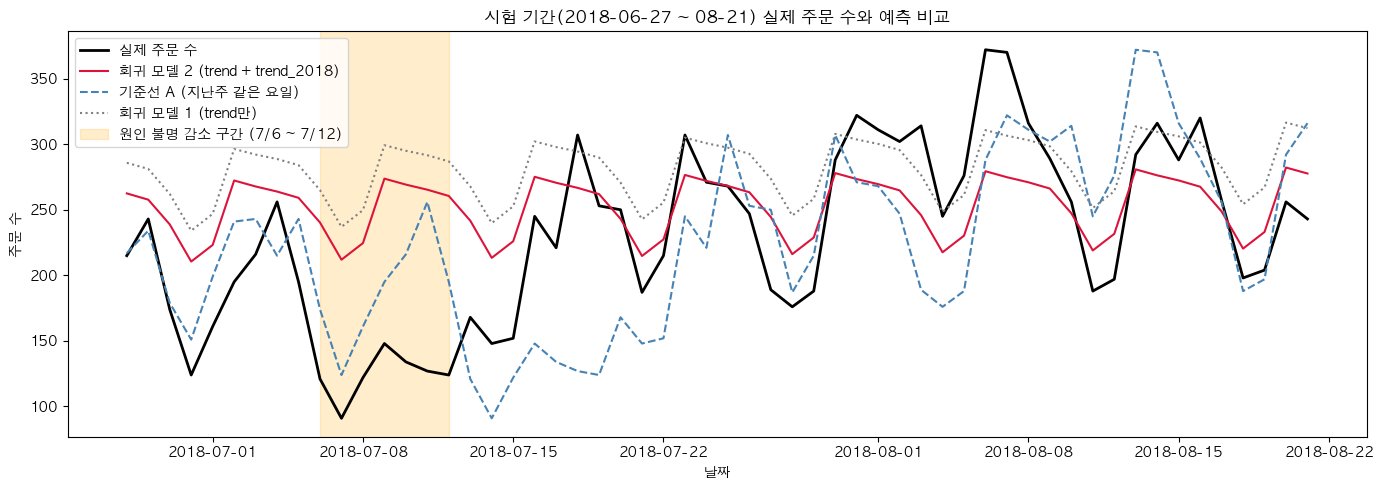

In [12]:
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(test['order_date'], test['cnt'], color='black', linewidth=2, label='실제 주문 수')
ax.plot(test['order_date'], test['pred_reg2'], color='crimson', label='회귀 모델 2 (trend + trend_2018)')
ax.plot(test['order_date'], test['pred_last_week'], color='steelblue', linestyle='--', label='기준선 A (지난주 같은 요일)')
ax.plot(test['order_date'], test['pred_reg'], color='gray', linestyle=':', label='회귀 모델 1 (trend만)')

# 원인 불명 감소 구간 표시
ax.axvspan(pd.to_datetime('2018-07-06'), pd.to_datetime('2018-07-12'),
           color='orange', alpha=0.2, label='원인 불명 감소 구간 (7/6 ~ 7/12)')

ax.set_title('시험 기간(2018-06-27 ~ 08-21) 실제 주문 수와 예측 비교')
ax.set_xlabel('날짜')
ax.set_ylabel('주문 수')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

- 7/6 ~ 7/12(원인 미확인 구간)에서는 모든 방법이 실제보다 높게 예측
- 미리 알 수 없는 사건은 예측만으로는 대응이 어려움

## 결론
- 회귀 모델은 요일, 공휴일, 이벤트처럼 미리 알 수 있는 요인을 반영하는 데 강점
- 최근 실적 기반 예측은 갑작스러운 변화를 빨리 따라가는 데 강점
- 회귀 모델로 기본 물량을 예측하고, 예측과 실제 차이가 커지면 따로 확인하는 방식이 맞다고 판단

## 한계
- 증가 속도가 바뀌는 시점(2018-01-01)은 그래프를 보고 정함. 여러 시점을 비교해서 오차가 가장 작은 지점을 찾는 건 해보지 못함
- 테스트 기간 8주에 이벤트, 공휴일이 없어서 그런 날의 예측 성능은 확인 못 함
- 베이스라인과 회귀 모델이 쓰는 정보 조건이 다름 (베이스라인은 직전 주 실제 값 사용)